# Módulo 4 — Autocovariância, ACF e PACF

## Seção 3 — Função de autocorrelação parcial (PACF): projeção linear, Yule–Walker e estimação

**Estado:** versão para revisão científica e pedagógica.  
**Pré-requisitos:** estacionariedade fraca, autocovariância, ACF teórica e amostral (Seções 1–2); solução de sistemas lineares, covariância e regressão linear elementar.  
**Ambiente computacional:** Python 3 com NumPy, Matplotlib e Statsmodels; os experimentos são sintéticos.

**Fundamentação acadêmica consultada:** Morettin e Toloi, *Análise de Séries Temporais — Modelos lineares univariados*, v. 1, 3ª ed., **§5.2.5, pp. 138–139, eqs. (5.66)–(5.67)** (páginas 157–158 do PDF do projeto): definição da função de autocorrelação parcial como último coeficiente de regressão autorregressiva de ordem $k$, equações de Yule–Walker e comportamento típico de AR/MA. **Complementação didática original:** construção pela regressão dos extremos após controle das defasagens intermediárias, dedução explícita do caso de ordem 2, exemplos numéricos, algoritmos e advertências sobre interpretação amostral.

### Objetivos de aprendizagem

Ao final, você deverá explicar por que a ACF e a PACF não são equivalentes; interpretar autocorrelação parcial como associação **linear residual**; deduzir a fórmula de ordem 2; construir e resolver Yule–Walker; estimar a PACF manualmente e em Statsmodels; reconhecer o corte teórico da PACF de AR($p$) e os limites da identificação por gráficos.

### 1. A motivação: associação direta ou transmitida por um instante intermediário?

Imagine que $Z_t$ seja correlacionado com $Z_{t+2}$. Isso pode acontecer porque o processo guarda informação diretamente por dois instantes ou porque a associação é transmitida por $Z_{t+1}$. A ACF, $\rho(2)$, resume a associação linear total entre os extremos. A **PACF de defasagem 2** mede sua associação linear **depois de controlar $Z_{t+1}$**.

"Controlar" não significa apagar toda dependência probabilística: significa remover a componente previsível por **projeção linear** nas variáveis intermediárias. PACF nula não prova independência condicional em geral e, por si só, não demonstra causalidade.

### 2. Definição formal em termos de projeção linear

Considere $Z_t$ fracamente estacionário, com variância estritamente positiva. Para uma defasagem $k\ge2$, projete linearmente as variáveis centradas $Z_t-\mu$ e $Z_{t-k}-\mu$ sobre o espaço gerado por

$$
Z_{t-1}-\mu,\;Z_{t-2}-\mu,\;\ldots,\;Z_{t-k+1}-\mu.
$$

Sejam $R_t$ e $R_{t-k}$ os **resíduos dessas projeções**. Quando ambas as variâncias residuais são positivas, definimos a autocorrelação parcial:

$$
\boxed{\alpha(k)=\mathrm{Corr}(R_t,R_{t-k}).}
$$

No caso $k=1$ não há instantes intermediários a controlar; portanto,

$$
\boxed{\alpha(1)=\rho(1).}
$$

Uma definição equivalente, para matrizes de covariância adequadamente invertíveis, é $\alpha(k)=\phi_{kk}$: o **último coeficiente** da melhor projeção linear de $Z_t-\mu$ sobre as últimas $k$ observações centradas,

$$
Z_t-\mu\approx\phi_{k1}(Z_{t-1}-\mu)+\cdots+\phi_{kk}(Z_{t-k}-\mu).
$$

O símbolo $\approx$ indica projeção de mínimos quadrados na população, não uma igualdade exata de variáveis aleatórias. A notação $\alpha(k)$ representa a PACF neste livro; os coeficientes $\phi_{kj}$ referem-se à ordem $k$, e não aos parâmetros de um único modelo ajustado para todas as ordens.

### 3. Dedução completa para defasagem 2

Escreva as variáveis centradas $X=Z_t-\mu$, $Y=Z_{t-1}-\mu$ e $W=Z_{t-2}-\mu$. Todas têm variância $\gamma(0)$. Para retirar linearmente o efeito de $Y$ de $X$ e de $W$, consideramos

$$
R_X=X-aY,\qquad R_W=W-bY.
$$

Os coeficientes de projeção minimizam $E[(X-aY)^2]$ e $E[(W-bY)^2]$. Derivando as duas funções quadráticas em relação aos coeficientes,

$$
a=\frac{\mathrm{Cov}(X,Y)}{\mathrm{Var}(Y)}=\rho(1),
\qquad
b=\frac{\mathrm{Cov}(W,Y)}{\mathrm{Var}(Y)}=\rho(1).
$$

Logo,

$$
R_X=X-\rho(1)Y,\qquad R_W=W-\rho(1)Y.
$$

Expanda a covariância dos resíduos:

$$
\begin{aligned}
\mathrm{Cov}(R_X,R_W)
&=\gamma(2)-\rho(1)\gamma(1)-\rho(1)\gamma(1)
  +\rho(1)^2\gamma(0)\\
&=\gamma(0)[\rho(2)-\rho(1)^2].
\end{aligned}
$$

Para cada resíduo, a variância é

$$
\mathrm{Var}(R_X)=\mathrm{Var}(R_W)=\gamma(0)[1-\rho(1)^2].
$$

Dividindo a covariância residual pelo produto dos desvios padrão residuais, obtemos

$$
\boxed{\alpha(2)=\frac{\rho(2)-\rho(1)^2}{1-\rho(1)^2},\qquad |\rho(1)|<1.}
$$

A condição $|\rho(1)|<1$ evita variâncias residuais nulas. O numerador mostra quanto da associação de segunda defasagem **não é explicado pelo caminho linear via defasagem 1**.

### 4. Exemplo numérico resolvido

Suponha que a ACF teórica satisfaça $\rho(1)=0{,}6$ e $\rho(2)=0{,}2$. Então:

$$
\begin{aligned}
\alpha(2)
&=\frac{0{,}2-0{,}6^2}{1-0{,}6^2}\\
&=\frac{-0{,}16}{0{,}64}\\
&=\boxed{-0{,}25}.
\end{aligned}
$$

A autocorrelação total na defasagem 2 é positiva, mas a autocorrelação **parcial** é negativa. Isso não é contradição: estão sendo medidas relações lineares diferentes. Esse conjunto de valores é compatível, por exemplo, com um AR(2) estacionário cujos coeficientes são $\phi_1=0{,}75$ e $\phi_2=-0{,}25$.

### 5. Yule–Walker: definição operacional geral

Considere a melhor previsão linear de $Z_t-\mu$ com as últimas $k$ observações. O erro de projeção deve ser ortogonal a cada regressor. Multiplicando pelo regressor $Z_{t-j}-\mu$ e tomando a esperança, obtemos, para $j=1,\ldots,k$,

$$
\gamma(j)=\sum_{i=1}^{k}\phi_{ki}\gamma(j-i).
$$

Dividindo por $\gamma(0)>0$, chegamos ao sistema de Yule–Walker:

$$
\underbrace{\begin{pmatrix}
1&\rho(1)&\cdots&\rho(k-1)\\
\rho(1)&1&\cdots&\rho(k-2)\\
\vdots&\vdots&\ddots&\vdots\\
\rho(k-1)&\rho(k-2)&\cdots&1
\end{pmatrix}}_{\mathbf R_k}
\underbrace{\begin{pmatrix}\phi_{k1}\\\phi_{k2}\\\vdots\\\phi_{kk}\end{pmatrix}}_{\boldsymbol\phi_k}
=
\underbrace{\begin{pmatrix}\rho(1)\\\rho(2)\\\vdots\\\rho(k)\end{pmatrix}}_{\mathbf r_k}.
$$

A última componente da solução é

$$
\boxed{\alpha(k)=\phi_{kk}.}
$$

Essa é a construção descrita por Morettin e Toloi na §5.2.5. Se $\mathbf R_k$ for singular, a solução pode não ser única; a interpretação como coeficiente de uma projeção linear precisa então de cuidados adicionais.

#### 5.1 Resolvendo o caso $k=2$ como sistema

$$
\begin{pmatrix}1&\rho(1)\\\rho(1)&1\end{pmatrix}
\begin{pmatrix}\phi_{21}\\\phi_{22}\end{pmatrix}
=
\begin{pmatrix}\rho(1)\\\rho(2)\end{pmatrix}.
$$

Da primeira linha, $\phi_{21}=\rho(1)-\rho(1)\phi_{22}$. Substituindo na segunda, chegamos a

$$
\phi_{22}=\frac{\rho(2)-\rho(1)^2}{1-\rho(1)^2},
$$

que reproduz a fórmula obtida pela correlação dos resíduos. Essa concordância conecta **interpretação geométrica** e **método algébrico**.

### 6. Comportamento teórico de AR e MA e limites da identificação

Para um processo autorregressivo AR($p$) **causal estacionário**, a PACF teórica é nula nas defasagens superiores a $p$, sob as condições usuais de não degenerescência. Dizemos que ela apresenta **corte** na ordem $p$. Já a ACF de um AR($p$) geralmente decai gradualmente.

No caso AR(1), $Z_t=\phi Z_{t-1}+\varepsilon_t$ com $|\phi|<1$,

$$
\rho(k)=\phi^{|k|}.
$$

Assim,

$$
\alpha(1)=\phi,\qquad
\alpha(k)=0\quad (k\ge2).
$$

Para MA(1), o comportamento típico é inverso: a **ACF** corta após a defasagem 1, enquanto a PACF geralmente decai gradualmente. Essas características orientam a construção de candidatos de modelos, mas **não garantem a identificação correta** a partir de gráficos amostrais. A referência do livro é a §5.2.5, pp. 138–139.

### 7. Python — cálculo manual de $\alpha(2)$ e implementação por biblioteca

Primeiro reproduza o exemplo $\rho(1)=0{,}6$, $\rho(2)=0{,}2$:

In [ ]:
import numpy as np

rho1, rho2 = 0.6, 0.2
R2 = np.array([[1.0, rho1], [rho1, 1.0]])
r2 = np.array([rho1, rho2])
coeficientes = np.linalg.solve(R2, r2)
print(coeficientes)
# Esperado: [0.75, -0.25]

pacf2 = (rho2 - rho1**2) / (1 - rho1**2)
assert np.isclose(coeficientes[-1], pacf2)


`np.linalg.solve(A, b)` resolve o sistema $A\mathbf x=\mathbf b$ sem calcular explicitamente a matriz inversa. O resultado tem dois coeficientes; o **último** é a PACF de ordem 2. O método pressupõe matriz quadrada não singular.

Agora simulamos séries AR(1) e AR(2) e estimamos suas PACFs. Usaremos `method="ywm"` em `statsmodels.tsa.stattools.pacf`, método de Yule–Walker com autocovariância de divisor $N$; isso explicita a convenção e facilita a comparação com a Seção 2.

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import pacf

n, descarte, max_lag = 800, 400, 25

rng1 = np.random.default_rng(20261117)
e1 = rng1.normal(size=n + descarte)
ar1 = np.zeros(n + descarte)
for t in range(1, len(ar1)):
    ar1[t] = 0.65 * ar1[t-1] + e1[t]
ar1 = ar1[descarte:]

rng2 = np.random.default_rng(20261118)
e2 = rng2.normal(size=n + descarte)
ar2 = np.zeros(n + descarte)
for t in range(2, len(ar2)):
    ar2[t] = 0.75 * ar2[t-1] - 0.25 * ar2[t-2] + e2[t]
ar2 = ar2[descarte:]

p1 = pacf(ar1, nlags=max_lag, method="ywm")
p2 = pacf(ar2, nlags=max_lag, method="ywm")

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ax, p, title in [
    (axes[0], p1, "PACF estimada — AR(1)"),
    (axes[1], p2, "PACF estimada — AR(2)")
]:
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.vlines(np.arange(max_lag + 1), 0, p)
    ax.set(title=title, ylabel="PACF")
axes[1].set_xlabel("Defasagem h")
plt.tight_layout()
plt.show()


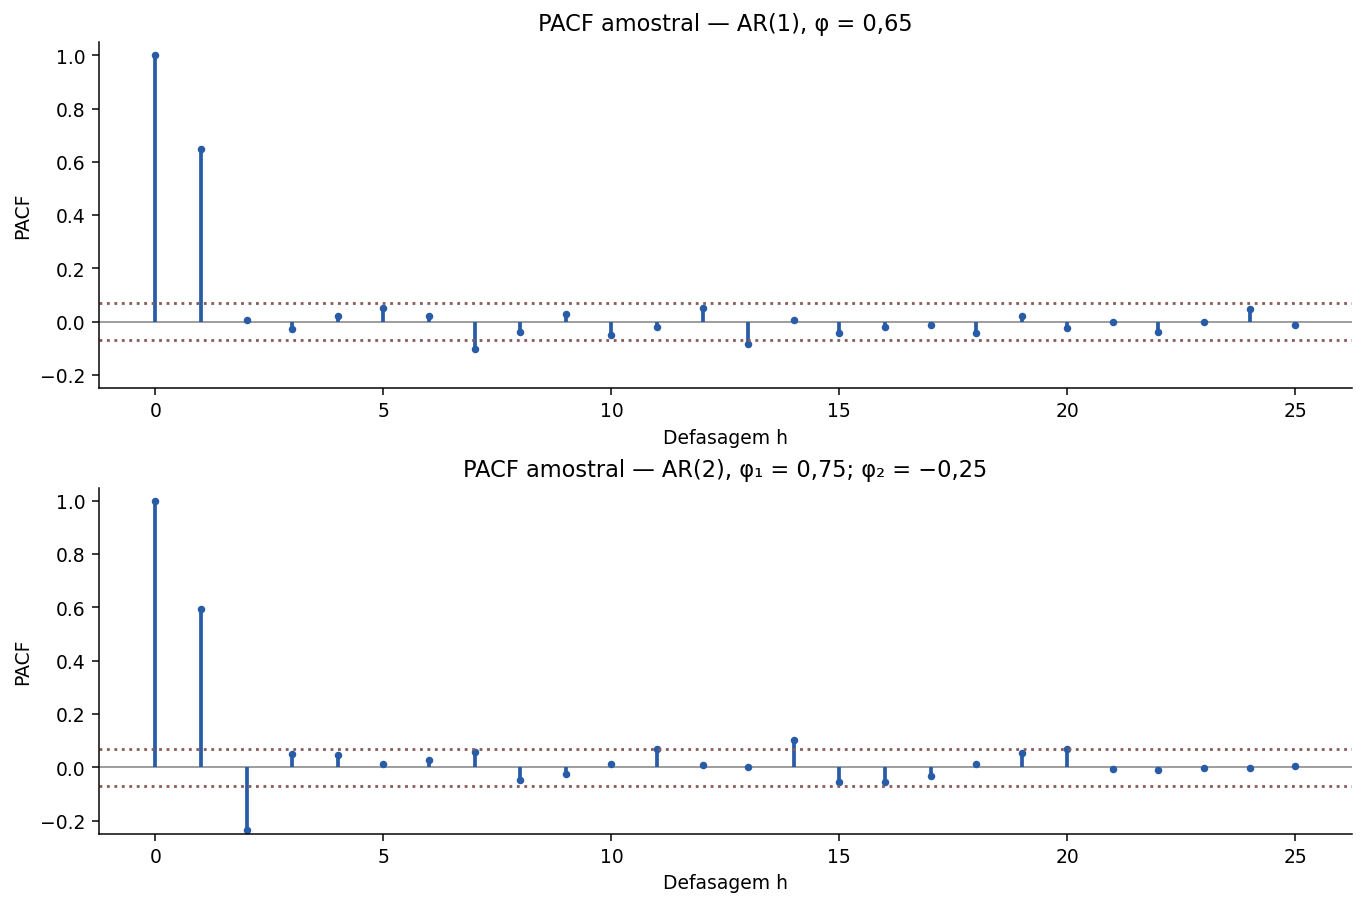

*Figura 2 — PACFs estimadas em realizações sintéticas de AR(1) e AR(2). O corte é uma propriedade da PACF **teórica**; nas amostras, estimativas em defasagens posteriores não serão exatamente nulas.*

**Interpretação:** esperamos um sinal dominante na defasagem 1 do AR(1) e nas defasagens 1 e 2 do AR(2). Pequenas oscilações posteriores são normais em amostras finitas. Não escolha uma ordem de modelo usando somente o número de barras que ultrapassam uma linha horizontal; complemente com adequação dos resíduos, parcimônia, estabilidade e avaliação fora da amostra no capítulo apropriado.

### 8. Cuidados metodológicos e limites

1. **A PACF é parcial no sentido linear.** Resíduos de projeções lineares não tornam variáveis automaticamente independentes; essa interpretação exige hipóteses adicionais específicas.
2. **Amostra e população diferem.** A PACF estimada depende do tamanho amostral, de sua convenção de estimação e da hipótese aproximada de estacionariedade.
3. **Ordem não é causalidade.** Uma PACF forte em $h=2$ não demonstra que o valor de dois instantes atrás causa o atual.
4. **Pré-processamento é relevante.** Tendência, sazonalidade e mudanças de regime não tratadas podem gerar PACFs enganosas.
5. **Há vários estimadores.** Statsmodels oferece Yule–Walker, mínimos quadrados, Levinson–Durbin e outros, com resultados não necessariamente idênticos em amostras pequenas; registre o método usado.
6. **Matriz singular.** A definição por Yule–Walker requer cuidado quando os regressores são perfeitamente linearmente dependentes.

### 9. Exercícios graduais

1. **Conceitual.** Explique com suas palavras a diferença entre $\rho(2)$ e $\alpha(2)$.
2. **Cálculo.** Se $\rho(1)=0{,}4$ e $\rho(2)=0{,}1$, calcule a PACF na defasagem 2, mostrando numerador e denominador.
3. **Demonstração.** Partindo da ortogonalidade do erro da projeção, derive as duas equações de Yule–Walker para $k=2$.
4. **Programação.** Escreva pseudocódigo para calcular $\phi_{kk}$ a partir das $k$ primeiras autocorrelações amostrais, criando uma matriz Toeplitz e resolvendo o sistema linear. Depois implemente sem utilizar `pacf`.
5. **Análise crítica.** Compare as PACFs de uma série de ruído branco e de sua primeira diferença; explique por que diferenciar desnecessariamente pode criar novos padrões de dependência.

**Resposta selecionada, exercício 2:**

$$
\alpha(2)=\frac{0{,}1-0{,}4^2}{1-0{,}4^2}=\frac{-0{,}06}{0{,}84}\approx -0{,}07143.
$$

### Síntese e referências

A ACF mede a associação linear total em uma defasagem; a PACF mede a associação linear entre extremos após remover efeitos lineares dos instantes intermediários. A construção de Yule–Walker formaliza essa ideia e permite estimá-la computacionalmente. O corte teórico da PACF em AR($p$) é uma ferramenta de identificação, mas seu análogo amostral é apenas aproximado.

- MORETTIN, P. A.; TOLOI, C. M. C. *Análise de Séries Temporais: Modelos lineares univariados*, v. 1, 3ª ed., §5.2.5, pp. 138–139, eqs. (5.66)–(5.67). Consulta visual ao PDF local, pp. 157–158 do arquivo.
- `mapeamento-conteudos-series-temporais.md`, Bloco D e aula de modelos autorregressivos/FACP. Utilizado para continuidade pedagógica.
- Deduções detalhadas, exemplos numéricos, scripts e figuras: complementações didáticas originais, não transcrições do livro.